# Pedagogical exercise proposed: multi-task fine-tuning GPT-1 on larger NLI datasets and tests on RTE

This notebook explores an open question left by Radford et al. (2018) in *"Improving Language Understanding by Generative Pre-Training"*. GPT-1 outperforms previous methods on most entailment datasets, but underperforms on RTE, a small dataset (~2.5k training examples), where a multi-task BiLSTM baseline achieves better results (61.7% vs. 56.0% accuracy). The authors suggest that their model would likely benefit from multi-task training, but they do not explore it.

**Research question:** Does GPT-1 improve on RTE when it is also fine-tuned on a larger entailment dataset (MNLI)?

I would like to investigate the model capacities when a bigger dataset is shown during fine-tuning and try to connect this to the way human beings learn.

**Experimental conditions:**
- **A. Baseline:** fine-tuning on RTE only.
- **B. Control:** fine-tuning on MNLI only, evaluated on RTE.
- **C. Sequential:** fine-tuning on MNLI, then on RTE.
- **D. Multi-task:** joint fine-tuning on MNLI and RTE.


**Setup:** We use the original pre-trained GPT-1 (`openai-community/openai-gpt`) with the paper's input transformation (`<s> premise <$> hypothesis <e>`) and fine-tuning hyperparameters. MNLI labels are mapped to two classes (entailment / not entailment) to match RTE, and a balanced subset of 20k MNLI examples is used. Each condition is run with 5 random seeds, and we report mean ± standard deviation of accuracy on the RTE validation set.

## Phase 1: Setup

We check the available GPU (Nvidia RTX-4060) and import the required libraries.

In [ ]:
import numpy as np, matplotlib.pyplot as plt, torch, transformers, datasets, evaluate, gc, pandas as pd
from collections import Counter
from datasets import concatenate_datasets
from transformers import DataCollatorWithPadding, TrainingArguments, Trainer, set_seed
from pathlib import Path
from scipy import stats

# Let's check everithing is fine and GPU is available

print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():

   x = torch.randn(4000,4000, device="cuda")
   y = x@x
   print("Product in", y.device)

torch: 2.14.1+cu126
transformers: 4.57.6
GPU available: True
Product in cuda:0


In [2]:
main = Path.cwd()
models    = main / "models"
results = main / "results"
figures    = main / "figures"

for carpeta in [models, results, figures]:
    carpeta.mkdir(exist_ok=True)

results_file = results / "results.csv"

def done(condition, seed):
    if not results_file.exists():
        return False
    df = pd.read_csv(results_file)
    return ((df["condition"] == condition) & (df["seed"] == seed)).any()

def save_results(row):
    headings = not results_file.exists()
    pd.DataFrame([row]).to_csv(results_file, mode="a",
                                header=headings, index=False)

def free_memory():
    gc.collect()
    torch.cuda.empty_cache()


Now we import the tokenizer for GPT-1 (a BPE system) and try it

In [3]:
from transformers import OpenAIGPTTokenizer, OpenAIGPTForSequenceClassification

tokenizer = OpenAIGPTTokenizer.from_pretrained("openai-community/openai-gpt")
print("Vocabulary lenght:", len(tokenizer))

phrase = "The cat sat unbelievably comfortable on me."
tokens = tokenizer.tokenize(phrase)

print(tokens)

print(tokenizer.tokenize("Tokenization of hyperparameters in transformers"))

Vocabulary lenght: 40478
['the</w>', 'cat</w>', 'sat</w>', 'unbelievably</w>', 'comfortable</w>', 'on</w>', 'me</w>', '.</w>']
['to', 'ken', 'ization</w>', 'of</w>', 'hyper', 'parameters</w>', 'in</w>', 'trans', 'form', 'ers</w>']


We observe that everything is in lowercase (text normalization) and the . is a single token. We also observe that with bigger and less usual words such as hyperparameters, the tokenizer breaks them apart. 

## Phase 2: Load and explore the RTE and MNLI datasets

The NLP task we're tackling is called natural language inference (NLI). It involves a pair of sentences and the model has to determine if the relation is of entailment or not (there could also be a 'neutral' class). 

    For example:
        Premise: "Ann bought a red car yesterday."
        Hypothesis: "Ann has a car."
        Expected answer: entailment.

Now we load the two sets and explore them.

In [4]:
rte = datasets.load_dataset("nyu-mll/glue", "rte") # That's the official name in Hugging Face
print(rte)

names_rte = rte["train"].features["label"].names
print("Classes:", names_rte)

for i in range(3):
    example = rte["train"][i]
    print(f"\nExample number {i+1}")
    print("Premise:", example["sentence1"])
    print("Hypothesis", example["sentence2"])
    print("Label:", example["label"], names_rte[example["label"]])

print("\nIn the test set labels are hidden:", rte["test"][0]["label"]) 


DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3000
    })
})
Classes: ['entailment', 'not_entailment']

Example number 1
Premise: No Weapons of Mass Destruction Found in Iraq Yet.
Hypothesis Weapons of Mass Destruction Found in Iraq.
Label: 1 not_entailment

Example number 2
Premise: A place of sorrow, after Pope John Paul II died, became a place of celebration, as Roman Catholic faithful gathered in downtown Chicago to mark the installation of new Pope Benedict XVI.
Hypothesis Pope Benedict XVI is the new leader of the Roman Catholic Church.
Label: 0 entailment

Example number 3
Premise: Herceptin was already approved to treat the sickest breast cancer patients, and the company said, Monday, 

We see if the classes are balanced. A naive baseline could be to always predict the majority class (therefore the 56% of GPT-1 should be above this value). The fact that test labels are hidden is problematic, since we will have to evaluate in the validation set, which is smaller. We explore it.

In [6]:
for split in ["train", "validation"]:
    count = Counter(rte[split]["label"])
    print(count)
    total = sum(count.values())
    print(f"{split}: {total} examples found")

majoritary_class = max(count.values())
print(f"The proportion of the majoritary class is {round(majoritary_class/total*100,2)}%")


Counter({0: 1249, 1: 1241})
train: 2490 examples found
Counter({0: 146, 1: 131})
validation: 277 examples found
The proportion of the majoritary class is 52.71%


All examples must be under 509 tokens (512 if we take into account the special tokens). As said in the paper, that's the token limits the authors set.

In [7]:
def len_tokens(premise, hypothesis):
    # We have to add the three special tokens for fine tuning in language entailment (<s>, $ and <e>)
    return len(tokenizer.tokenize(premise)) + len(tokenizer.tokenize(hypothesis)) + 3

long_rte = np.array([
    len_tokens(example["sentence1"], example["sentence2"]) for example in rte["train"]
])

print(f"Max: {long_rte.max()}")

Max: 288


We now load and explore the MNLI set in the same way.

In [8]:
mnli = datasets.load_dataset("nyu-mll/glue", "mnli") # That's the official name in Hugging Face
print(mnli)

names_mnli = mnli["train"].features["label"].names
print("Classes:", names_mnli)

for i in range(3):
    example = mnli["train"][i]
    print(f"\nExample number {i+1}")
    print("Premise:", example["premise"])
    print("Hypothesis", example["hypothesis"])
    print("Label:", example["label"], names_mnli[example["label"]])

print("\nIn the test set labels are hidden:", mnli["test_matched"][0]["label"]) 

DatasetDict({
    train: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 392702
    })
    validation_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9815
    })
    validation_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9832
    })
    test_matched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9796
    })
    test_mismatched: Dataset({
        features: ['premise', 'hypothesis', 'label', 'idx'],
        num_rows: 9847
    })
})
Classes: ['entailment', 'neutral', 'contradiction']

Example number 1
Premise: Conceptually cream skimming has two basic dimensions - product and geography.
Hypothesis Product and geography are what make cream skimming work. 
Label: 1 neutral

Example number 2
Premise: you know during the season and i guess at at your level uh you lose them to the next level if if they dec

We have to binarize the tags in MNLI to make them comparable to RTE. Neutral and contradiction will become 1 (not entailed). We'll also choose 20,000 examples, since the capacity is limited, but it is still a large set to work with and test the hypothesis.

If we only binarized MNLI, there would be a big imbalance between both classes (1/3 vs 2/3), and this might bias the model on the RTE set. We could change the loss function to penalize the dominant class, but we chose something simpler. We take 10,000 entailment examples and 5,000 of each of the other two classes, so both classes are balanced after binarizing.

In [ ]:
seed = 0
mnli_mixed = mnli["train"].shuffle(seed)

ent = mnli_mixed.filter(lambda e: e["label"] == 0).select(range(10000))
neu = mnli_mixed.filter(lambda e: e["label"] == 1).select(range(5000))
con = mnli_mixed.filter(lambda e: e["label"] == 2).select(range(5000))

mnli_sub = concatenate_datasets([ent, neu, con]).shuffle(seed=42)

count = Counter(mnli_sub["label"])

print(count)
print("Total:", len(mnli_sub))
print("Examples:", mnli_sub["label"][:10])

Counter({0: 10000, 1: 5000, 2: 5000})
Equal subset: {'entailment': 10000, 'neutral': 5000, 'contradiction': 5000}
Total: 20000
Examples: [1, 2, 1, 1, 2, 1, 1, 2, 0, 0]


## Phase 3: Input transformations, tokenizer and model load

As the authors explain in the paper, the key concept that makes GPT work well in multiple different tasks is the fine-tuning through input transformations (although zero-shot behaviour raises the question of whether this is completely true). These are special tokens we use to give some certain meaning and coherence to the tokens we introduce. In the case of language entailment, the authors propose using \<s> at the beginning of the premise, <$> to separate the premise and the hypothesis and \<e> to end the hypothesis. This last token is crucial. Since it goes at the end and the self-attention is masked, it is the only token that sees the whole sentence. 

Note that we will be using a GPU for this experiment. GPUs require tensors of the exact same length. However, the different examples we have in the dataset differ in their sizes. For this reason, we use a special padding token (`<pad>`) to reach the same dimension. We then apply a mask to these characters so that the model doesn't pay attention to the filler values. It is worth remarking that our padding token will be added at the end of each example (behind \<e>) so that the real values never "see" these tokens. This is due to the causal behaviour the authors explain in the paper. On the other hand, it is also interesting to remark that GPT was trained with contiguous text, so there were no dimensional problems like the one we are facing.

In [ ]:
input_transformations = {
    "bos_token": "<s>",    # Here we have to use the hugging face key names like "bos", otherwise we get error.
    "sep_token": "<$>",   
    "eos_token": "<e>",    
    "pad_token": "<pad>",  
}

news = tokenizer.add_special_tokens(input_transformations)

start_id      = tokenizer.convert_tokens_to_ids("<s>")
separation_id = tokenizer.convert_tokens_to_ids("<$>")
end_id        = tokenizer.convert_tokens_to_ids("<e>")
padding_id    = tokenizer.convert_tokens_to_ids("<pad>")

print("Size of the vocabulary:", len(tokenizer))
print("IDs:", start_id, separation_id, end_id, padding_id)

Size of the vocabulary: 40482
IDs: 40478 40479 40480 40481


In [10]:
max_len = 512 

def prepare(premise, hyptohesis):
    ids_p = tokenizer.encode(premise, add_special_tokens=False)
    ids_h = tokenizer.encode(hyptohesis, add_special_tokens=False)

    # In case the statement was longer than 512 characters, we cut the premise
    space_premise = max_len - 3 - len(ids_h)
    ids_p = ids_p[:space_premise]
    return [start_id] + ids_p + [separation_id] + ids_h + [end_id]

# We do an example
example = rte["train"][0]
ids=prepare(example["sentence1"], example["sentence2"])
tokens = tokenizer.convert_ids_to_tokens(ids)
print(tokens)

['<s>', 'no</w>', 'weapons</w>', 'of</w>', 'mass</w>', 'destruction</w>', 'found</w>', 'in</w>', 'iraq</w>', 'yet</w>', '.</w>', '<$>', 'weapons</w>', 'of</w>', 'mass</w>', 'destruction</w>', 'found</w>', 'in</w>', 'iraq</w>', '.</w>', '<e>']


In [11]:
def process(batch, premise_col, hypothesis_col, binarize):
    ids=[prepare(p,h) for p, h in zip(batch[premise_col], batch[hypothesis_col])]
    tags = batch["label"]

    if binarize: # We do this for the MNLI set
        tags=[0 if y==0 else 1 for y in tags]

    return {
        "input_ids" : ids,
        "attention_mask": [[1] * len(x) for x in ids],
        "labels": tags,
    }

args_rte = dict(premise_col="sentence1", hypothesis_col="sentence2", binarize=False)
args_mnli = dict(premise_col = "premise", hypothesis_col = "hypothesis", binarize = True)

rte_train = rte["train"].map(process, batched=True, fn_kwargs=args_rte, remove_columns=rte["train"].column_names)
#Dataset.map is a HF method transforming one dataset into another throughout the function process and the arguments previously defined.
rte_val = rte["validation"].map(process, batched=True, fn_kwargs=args_rte, remove_columns=rte["validation"].column_names)

mnli_train = mnli_sub.map(process, batched=True, fn_kwargs=args_mnli, remove_columns=mnli_sub.column_names)

print(rte_train)
print(mnli_train)

Map: 100%|██████████| 20000/20000 [00:18<00:00, 1056.56 examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 2490
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 20000
})


Now we load the model, but without the final head that predicts the following word. What we need is the main structure, the transformer, to process sentences and fine-tune it. Instead, a new classification head with two outputs is added on top.

In [12]:
def create_model():
    model = OpenAIGPTForSequenceClassification.from_pretrained(
        "openai-community/openai-gpt", num_labels=2
    )
    model.resize_token_embeddings(len(tokenizer))
    model.config.pad_token_id=padding_id
    return model

model = create_model()

print(model.transformer.tokens_embed)     # W_e: embeddings matrix
print(model.transformer.positions_embed)  # W_p: position matrix
print(model.score)                        # W_y: classification head
n_param = sum(p.numel() for p in model.parameters())
print(n_param)

Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Embedding(40482, 768)
Embedding(512, 768)
Linear(in_features=768, out_features=2, bias=False)
116539392


In [13]:
collator = DataCollatorWithPadding(tokenizer)
batch = collator([rte_train[i] for i in range(4)]) # collator is an object but it's dessigned to be callable.
print(batch) 

for key, tensor in batch.items():
    print(key, tuple(tensor.shape))

model = model.to("cuda")
model.eval() # Since this is a little test we don't need the dropout but all the neurons, like the complte model authors obtained.

with torch.no_grad(): # For the test we don't need to update gradient values
    output = model(**{k:v.to("cuda") for k, v in batch.items()})

print("\nLogits:\n", output.logits)
print("Probabilities:\n", torch.softmax(output.logits, dim=-1))
print("Real tag:", batch["labels"].tolist())


{'input_ids': tensor([[40478,   664,  3854,   498,  5547,  7716,  1132,   500, 20793,  1340,
           239, 40479,  3854,   498,  5547,  7716,  1132,   500, 20793,   239,
         40480, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481,
         40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481,
         40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481,
         40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481,
         40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481, 40481],
        [40478,   246,  1082,   498,  8617,   240,   861, 13822,  2476,  3127,
          7735,  1802,   240,  2259,   246,  1082,   498, 11009,   240,   557,
          7977, 14044, 12068,  3853,   500,  8249,  7490,   485,  2546,   481,
         31791,   498,   783, 13822, 17437,    34,  4138,   239, 40479, 13822,
         17437,    34,  4138,   544,   481,   783,  4253,   498,   481,  7977,
         14044,  3430,   239, 40480, 

## Phase 4: Baseline model, fine-tuning on RTE dataset.

This model will be our baseline. We will be replicating the same experiment the authors did in their paper. Note that we will not obtain the same result since the loss function is not the same (we are not including the language modelling objective). However, in Table 5 the authors showed a result of 54.4% on RTE without the auxiliary loss, so that's the performance we expect to reach here (note that they evaluate on the test set and we use the validation set). Here we will train the model exclusively on the RTE dataset and compare it to the other models' results.

We will start defining the framework of the models according to the hyperparameters in the paper (the batch of 32 is split into 16 × 2 with gradient accumulation). We will re-use this setup in all the models we train and evaluate in order for them to be comparable.

In [14]:
# Hyperparameters of section 4 in the paper
LR = 6.25e-5
epochs = 3
batch = 16 # The GPU is not enough for 32-size batches
accumulation = 2
warmup = 0.002
weight_decay = 0.01

def metrics (eval_predictions):
    logits, tags = eval_predictions
    predictions = np.argmax(logits, axis=-1)
    return{
        "accuracy" : (predictions == tags).mean(),
        "pct_pred_enatailment" : (predictions == 0).mean(),
    }

def train (model, train_data, seed, directory):
    args = TrainingArguments(
        output_dir=directory,
        per_device_train_batch_size=batch,
        gradient_accumulation_steps=accumulation,
        per_device_eval_batch_size=32,
        learning_rate=LR,
        num_train_epochs=epochs,
        lr_scheduler_type="linear",
        warmup_ratio=warmup,
        weight_decay=weight_decay,
        bf16=True,
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=10,
        seed=seed,
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_data,
        eval_dataset=rte_val,
        data_collator=collator,
        compute_metrics=metrics,
    )
    trainer.train()
    return trainer  

We will do a little try with only one seed. If everything goes well, we will later add all the five seeds to see the results.

In [15]:
# Free the model from the previous phase
model = None
torch.cuda.empty_cache()

seed = 0
set_seed(seed)
model = create_model()

trainer = train(model, rte_train, seed, directory=str(results / "A_test_seed0"))

final = trainer.evaluate()
print(f"\nAccuracy in validation: {round(final['eval_accuracy']*100,2)} %")
print(f"Entailment predictions': {round(final['eval_pct_pred_enatailment']*100,2)}%")

Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.693600,0.700925,0.472924,0.000000
2,0.685900,0.690863,0.530686,0.563177
3,0.595300,0.730395,0.523466,0.620939



Accuracy in validation: 52.35 %
Entailment predictions': 62.09%


In [ ]:
seeds = [0,1,2,3,4]
condition = "A"
best_dir_A = models / f"best_model_{condition}"
for seed in seeds:

    if done(condition, seed):
        print(f"Already existing file for condition {condition} and seed {seed}")
        continue
    
    set_seed(seed)
    model = create_model()

    trainer = train(model, rte_train, seed, directory = str (results / f"{condition}_seed{seed}"))
    final = trainer.evaluate()
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

    row = {
        "condition": condition,
        "seed": seed,
        "accuracy": final["eval_accuracy"],
        "pct_entailment": final["eval_pct_pred_enatailment"],
        "loss_final": losses[-1],
    }
    save_results(row)

    print(f"[{condition}] seed {seed}: accuracy {round(row['accuracy']*100,2)}%, "
          f"entailment {round(row['pct_entailment']*100,2)}%")

    del trainer, model

    free_memory()

df = pd.read_csv(results_file)
df_A = df[df["condition"] == "A"]

print(df_A.to_string(index=False))
print(f"\n Condition {condition}: {round(df_A['accuracy'].mean()*100,2)}% ± {round(df_A['accuracy'].std()*100,2)}%"
      f"(n = {len(df_A)} seeds)")

Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.693600,0.700925,0.472924,0.000000
2,0.685900,0.690863,0.530686,0.563177
3,0.595300,0.730395,0.523466,0.620939


[A] seed 0: accuracy 52.35%, entailment 62.09%
The model of the seed 0 has been updated as the best one.


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.692100,0.690518,0.588448,0.736462
2,0.628900,0.676437,0.581227,0.454874
3,0.551200,0.756046,0.602888,0.700361


[A] seed 1: accuracy 60.29%, entailment 70.04%
The model of the seed 1 has been updated as the best one.


... (5 outputs left out)

[A] seed 3: accuracy 55.23%, entailment 62.82%


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.727200,0.699388,0.472924,0.000000
2,0.695200,0.690962,0.545126,0.664260
3,0.653900,0.720604,0.516245,0.628159


[A] seed 4: accuracy 51.62%, entailment 62.82%
condition  seed  accuracy  pct_entailment  loss_final
        A     0  0.523466        0.620939      0.5953
        A     1  0.602888        0.700361      0.5512
        A     2  0.559567        0.490975      0.5698
        A     3  0.552347        0.628159      0.5241
        A     4  0.516245        0.628159      0.6539

 Condition A: 55.09% ± 3.44%(n = 5 seeds)


The averaged results show the baseline is correctly reproduced: we obtain 55.09% ± 3.44, while the paper reports 54.4% without the auxiliary loss and 56.0% with it. We also observe a high variance between seeds.

## Phase 5: Fine-tuning on MNLI and test on RTE

We want to answer the question "Is every entailment set useful to predict on an NLI task?". This is interesting because MNLI is about very different topics (fiction, government reports, conversations, etc.) while RTE is only news. So the question might be reformulated as "Is entailment a global capacity or does it depend on the domain of the set?".

In [19]:
seeds = [0,1,2,3,4]
condition = "B"
best_dir_B = models / f"best_model_{condition}"
best_accuracy=0

for seed in seeds:

    if done(condition, seed):
        print(f"Already existing file for condition {condition} and seed {seed}")
        continue
    
    set_seed(seed)
    model = create_model()

    trainer = train(model, mnli_train, seed, directory = str (results / f"{condition}_seed{seed}"))
    final = trainer.evaluate()
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

    row = {
        "condition": condition,
        "seed": seed,
        "accuracy": final["eval_accuracy"],
        "pct_entailment": final["eval_pct_pred_enatailment"],
        "loss_final": losses[-1],
    }
    save_results(row)

    print(f"[{condition}] seed {seed}: accuracy {round(row['accuracy']*100, 2)} %",
          f"entailment {round(row['pct_entailment']*100,2)}%")

    
    if final["eval_accuracy"] > best_accuracy:
        best_accuracy = final["eval_accuracy"]
        trainer.save_model(str(best_dir_B))
        print(f"The model of the seed {seed} has been updated as the best one.")
        
    del trainer, model

    free_memory()

df = pd.read_csv(results_file)
df_B = df[df["condition"] == "B"]

print(df_B.to_string(index=False))
print(f"\n Condition {condition}: {round(df_B['accuracy'].mean()*100,2)}% ± {round(df_B['accuracy'].std()*100,2)}%"
      f"(n = {len(df_B)} seeds)")

Already existing file for condition B and seed 0


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.406700,0.778399,0.660650,0.714801
2,0.247000,0.947362,0.631769,0.671480
3,0.166200,1.307046,0.638989,0.671480


[B] seed 1: accuracy 63.9 % entailment 67.15%
The model of the seed 1 has been updated as the best one.


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.472000,0.768543,0.610108,0.729242
2,0.284900,0.847360,0.642599,0.631769
3,0.103300,1.298728,0.649819,0.718412


... (3 outputs left out)

[B] seed 3: accuracy 63.9 % entailment 67.15%


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.388900,0.828322,0.646209,0.685921
2,0.287300,0.895934,0.624549,0.664260
3,0.126800,1.371314,0.649819,0.703971


[B] seed 4: accuracy 64.98 % entailment 70.4%
condition  seed  accuracy  pct_entailment  loss_final
        B     0  0.628159        0.696751      0.1130
        B     1  0.638989        0.671480      0.1662
        B     2  0.649819        0.718412      0.1033
        B     3  0.638989        0.671480      0.1367
        B     4  0.649819        0.703971      0.1268

 Condition B: 64.12% ± 0.91%(n = 5 seeds)


Interestingly, MNLI-only reaches 64.12% ± 0.91 without seeing RTE at all, 9 points above the baseline and with much less variance. However, it predicts entailment in ~69% of the cases.

## Phase 6: Fine-tuning on an MNLI-fine-tuned model

We want to answer the question "Is it useful to fine-tune on RTE a model already fine-tuned on the same task (NLI)?". Phang et al. (2018) showed that training GPT on MNLI before fine-tuning it on RTE substantially improves its performance, an approach they call STILTs. And, it is the most direct answer to the authors' hypothesis, without being the exact same question. An interpretation linked to human learning could be "Is a domain expert able to learn variants of the field and perform equal or better than the variant expert?".


In [ ]:
seeds = [0,1,2,3,4]
condition = "C"
best_dir_C = models / f"best_model_{condition}"

for seed in seeds:

    if done(condition, seed):

        print(f"Already existing file for condition {condition} and seed {seed}")
        continue

    set_seed(seed)

    model = create_model()
    t1 = train(model, mnli_train, seed, directory=str(results / f"{condition}_seed{seed}_mnli"))
    model = t1.model
    del t1

    trainer = train(model, rte_train, seed, directory=str(results / f"{condition}_seed{seed}"))
    final = trainer.evaluate()
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

    row = {
        "condition": condition,
        "seed": seed,
        "accuracy": final["eval_accuracy"],
        "pct_entailment": final["eval_pct_pred_enatailment"],
        "loss_final": losses[-1],
    }
    save_results(row)

    print(f"[{condition}] seed {seed}: accuracy {round(row['accuracy']*100, 2)} %",
            f"entailment {round(row['pct_entailment']*100,2)}%")
        
    del trainer, model

    free_memory()

df = pd.read_csv(results_file)
df_C = df[df["condition"] == "C"]

print(df_C.to_string(index=False))
print(f"\n Condition {condition}: {round(df_C['accuracy'].mean()*100,2)}% ± {round(df_C['accuracy'].std()*100,2)}%"
        f"(n = {len(df_C)} seeds)")

Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.454100,0.789758,0.631769,0.700361
2,0.288500,1.021083,0.620939,0.732852
3,0.113000,1.471317,0.628159,0.696751


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.623100,0.659294,0.660650,0.642599
2,0.487200,0.747841,0.653430,0.570397
3,0.290400,0.918053,0.646209,0.606498


[C] seed 0: accuracy 64.62 % entailment 60.65%
The model of the seed 0 has been updated as the best one.


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.406700,0.778399,0.660650,0.714801
2,0.247000,0.947362,0.631769,0.671480
3,0.166200,1.307046,0.638989,0.671480


... (10 outputs left out)

Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.388900,0.828322,0.646209,0.685921
2,0.287300,0.895934,0.624549,0.664260
3,0.126800,1.371314,0.649819,0.703971


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.634300,0.654806,0.649819,0.552347
2,0.509000,0.677533,0.635379,0.624549
3,0.328900,0.822799,0.675090,0.649819


[C] seed 4: accuracy 67.51 % entailment 64.98%
condition  seed  accuracy  pct_entailment  loss_final
        C     0  0.646209        0.606498      0.2904
        C     1  0.660650        0.606498      0.3237
        C     2  0.667870        0.642599      0.3263
        C     3  0.685921        0.574007      0.2618
        C     4  0.675090        0.649819      0.3289

 Condition C: 66.71% ± 1.5%(n = 5 seeds)


Adding RTE after MNLI still helps and we obtain 66.71% ± 1.50, 2.6 points above MNLI-only.

## Phase 7: Multi-task training with MNLI and RTE datasets

We will use a combined dataset of MNLI and oversampled RTE. This is properly what the authors suggested in the paper and what the multi-task BiLSTM used (with one head per task). We would like to know if this way of training benefits the model more than the other ones.

We start by doing some checks on the ratio of values in the unified dataset and preparing it for the training.

In [24]:
print( f"The set mnli_train has a sahpe of {mnli_train.shape}")
print( f"The set rte_train has a sahpe of {rte_train.shape}")

if mnli_train.features!=rte_train.features:
    print ("Keys are not the same in both datasets")
    raise IndexError
else:
    print("Both sets have the exact same columns", mnli_train.features)

ratio = rte_train.shape[0]/mnli_train.shape[0]*100
print (f"The current ratio is of {ratio}%")

print(f"Is mnli_train binarized?: {mnli_train.unique("labels")==[1,0]}")

The set mnli_train has a sahpe of (20000, 3)
The set rte_train has a sahpe of (2490, 3)
Both sets have the exact same columns {'input_ids': List(Value('int32')), 'attention_mask': List(Value('int8')), 'labels': Value('int64')}
The current ratio is of 12.45%
Is mnli_train binarized?: True


We want to know how to properly mix the datasets. If the proportion of RTE is too small it might be diluted and not effective. On the other hand, if we replicate the examples too many times, we might overfit the model. In "Exploring the limits of transfer learning with a unified text-to-text transformer", Raffel et al. (2020) show that temperature-scaled mixing with T = 2 (taking the square root of the dataset sizes) gives reasonable results for most tasks. If we do the calculations


$\begin{align} ratio_{temp} = \frac{\sqrt{2490}}{\sqrt{20000}} \cdot 100 \approx 35.28\% \end{align}$

Therefore, we could multiply the RTE set by a factor of 

$\begin{align} multiplier = \frac{20000 \cdot 0.3528}{2490} = 2.83 \approx 3 \end{align}$

So we multiply RTE by a factor of 3.



In [ ]:
rte_multiplied = concatenate_datasets([rte_train] * 3)

print(len(rte_multiplied))
print(f"The new ratio is {round(len(rte_multiplied)/len(mnli_train)*100,2)}%")

concatenate_train = concatenate_datasets([mnli_train, rte_multiplied])
print(len(concatenate_train))

7470
The new ratio is 37.35%
27470


And now we repeat the same process as in the previous phases.

In [ ]:
seeds = [0,1,2,3,4]
condition = "D"
best_dir_D = models / f"best_model_{condition}"
for seed in seeds:

    if done(condition, seed):
        print(f"Already existing file for condition {condition} and seed {seed}")
        continue
    
    set_seed(seed)
    model = create_model()

    trainer = train(model, concatenate_train, seed, directory = str (results / f"{condition}_seed{seed}"))
    final = trainer.evaluate()
    losses = [h["loss"] for h in trainer.state.log_history if "loss" in h]

    row = {
        "condition": condition,
        "seed": seed,
        "accuracy": final["eval_accuracy"],
        "pct_entailment": final["eval_pct_pred_enatailment"],
        "loss_final": losses[-1],
    }
    save_results(row)

    print(f"[{condition}] seed {seed}: accuracy {round(row['accuracy']*100,2)}%, "
          f"entailment {round(row['pct_entailment']*100,2)}%")

    del trainer, model

    free_memory()

df = pd.read_csv(results_file)
df_D = df[df["condition"] == "D"]

print(df_D.to_string(index=False))
print(f"\n Condition {condition}: {round(df_D['accuracy'].mean()*100,2)}% ± {round(df_D['accuracy'].std()*100,2)}%"
      f"(n = {len(df_D)} seeds)")


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.369000,0.837978,0.671480,0.631769
2,0.226700,1.141018,0.660650,0.563177
3,0.173700,1.784817,0.664260,0.559567


[D] seed 0: accuracy 66.43%, entailment 55.96%
The model of the seed 0 has been updated as the best one.


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.447800,0.769259,0.620939,0.458484
2,0.231400,1.052569,0.664260,0.610108
3,0.109400,1.525915,0.657040,0.602888


[D] seed 1: accuracy 65.7%, entailment 60.29%


... (5 outputs left out)

[D] seed 3: accuracy 68.59%, entailment 56.68%


Some weights of OpenAIGPTForSequenceClassification were not initialized from the model checkpoint at openai-community/openai-gpt and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Pct Pred Enatailment
1,0.383800,0.781322,0.667870,0.592058
2,0.174400,1.153699,0.657040,0.552347
3,0.071600,1.761839,0.649819,0.552347


[D] seed 4: accuracy 64.98%, entailment 55.23%
condition  seed  accuracy  pct_entailment  loss_final
        D     0  0.664260        0.559567      0.1737
        D     1  0.657040        0.602888      0.1094
        D     2  0.693141        0.552347      0.0755
        D     3  0.685921        0.566787      0.0790
        D     4  0.649819        0.552347      0.0716

 Condition D: 67.0% ± 1.87%(n = 5 seeds)


Mixing both sets gives practically the same result as the sequential training: 67.00% ± 1.87. The way of introducing RTE does not seem to matter, although the bias towards entailment is lower here (~57%).

## Phase 8: Statistical results and conclusions

We will perform some tests to check the reliability of our results and we will also collect some figures that summarize the findings. The paired test can only be applied to the test between B and C, since the first model comes from the same seed. 

,condition,n,mean (%),std (%),CI95 low (%),CI95 high (%),pred. entailment (%)
0,A · RTE,5,55.09,3.44,50.82,59.36,61.37
1,B · MNLI,5,64.12,0.91,62.99,65.24,69.24
2,C · MNLI → RTE,5,66.71,1.50,64.86,68.57,61.59
3,D · MNLI + RTE×3,5,67.00,1.87,64.68,69.32,56.68


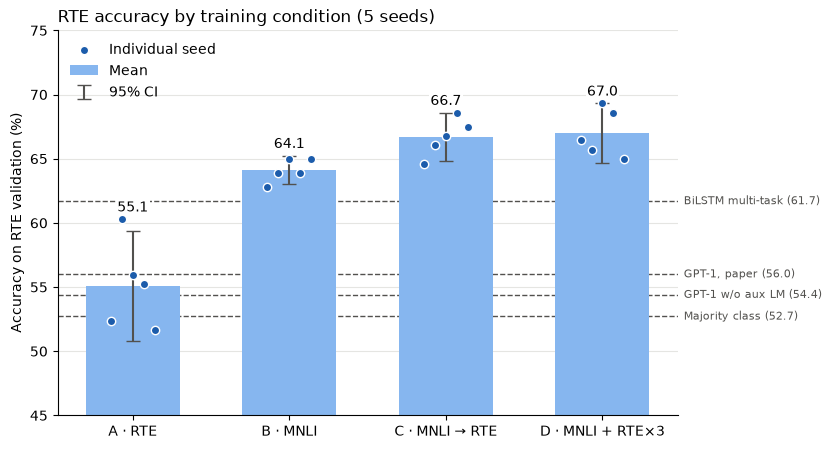

,pair,difference (pts),t (Welch),p (Welch),t (paired),p (paired)
0,A–D,11.9134,6.8045,0.0004,7.3063,0.0019
1,B–C,2.5993,3.3211,0.0139,4.8107,0.0086
2,C–D,0.2888,0.2697,0.7945,0.3255,0.7611


In [ ]:
df = pd.read_csv(results_file)

conds = ["A", "B", "C", "D"]
names = {"A": "A · RTE", "B": "B · MNLI", "C": "C · MNLI → RTE", "D": "D · MNLI + RTE×3"}
acc = {c: df[df["condition"] == c].sort_values("seed")["accuracy"].to_numpy() * 100 for c in conds}

# 1. Main table
rows = []
for c in conds:
    n, mean, sd = len(acc[c]), acc[c].mean(), acc[c].std(ddof=1)
    half = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    rows.append({
        "condition": names[c], "n": n, "mean (%)": mean, "std (%)": sd,
        "CI95 low (%)": mean - half, "CI95 high (%)": mean + half,
        "pred. entailment (%)": df[df["condition"] == c]["pct_entailment"].mean() * 100,
    })
summary = pd.DataFrame(rows).round(2)
display(summary)
summary.to_csv(results_file.parent / "summary.csv", index=False)

# 2. Bars (mean)

majority = max(Counter(rte["validation"]["label"]).values()) / len(rte["validation"]) * 100
references = {f"Majority class ({majority:.1f})": majority, "GPT-1 w/o aux LM (54.4)": 54.4,
              "GPT-1, paper (56.0)": 56.0, "BiLSTM multi-task (61.7)": 61.7}

x = np.arange(len(conds))
means = summary["mean (%)"].to_numpy()
errors = (summary["CI95 high (%)"] - means).to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x, means, width=0.6, color="#86b6ef", zorder=2, label="Mean")
ax.errorbar(x, means, yerr=errors, fmt="none", ecolor="#52514e", capsize=5, zorder=3, label="95% CI")
for i, c in enumerate(conds):
    ax.scatter(x[i] + np.linspace(-0.14, 0.14, len(acc[c])), acc[c], color="#1c5cab", edgecolors="white",
               zorder=4, label="Individual seed" if i == 0 else None)
    ax.text(x[i], max(means[i] + errors[i], acc[c].max()) + 0.6, f"{means[i]:.1f}", ha="center",
            bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
for label, value in references.items():
    ax.axhline(value, color="#52514e", linestyle="--", linewidth=1, zorder=1)
    ax.annotate(label, xy=(1.01, value), xycoords=("axes fraction", "data"), va="center", fontsize=8,
                color="#52514e", annotation_clip=False)

ax.set_xticks(x, [names[c] for c in conds])
ax.set_ylabel("Accuracy on RTE validation (%)")
ax.set_ylim(45, 75)
ax.set_title("RTE accuracy by training condition (5 seeds)", loc="left")
ax.grid(axis="y", color="#e5e5e2", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.savefig(figures / "accuracy_by_condition.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. t-tests
tests_df = []
for a, b in [("A", "D"), ("B", "C"), ("C", "D")]:
    welch = stats.ttest_ind(acc[b], acc[a], equal_var=False)
    paired = stats.ttest_rel(acc[b], acc[a])
    tests_df.append({"pair": f"{a}–{b}", "difference (pts)": acc[b].mean() - acc[a].mean(),
                  "t (Welch)": welch.statistic, "p (Welch)": welch.pvalue,
                  "t (paired)": paired.statistic, "p (paired)": paired.pvalue})
tests_df = pd.DataFrame(tests_df).round(4)
display(tests_df)
tests_df.to_csv(results_file.parent / "t_tests_welch_paired.csv", index=False)